# Lecture 6: Present Bias and Quasi-Hyperbolic Discounting

**Lecture 6 of 9** · [Series index](README.md)

*This lecture builds on [Lecture 1: Cass-Koopmans Competitive Equilibrium — solved with Newton's method](01_cass_koopmans_competitive_equilibrium.ipynb), which adapts [Cass-Koopmans Competitive Equilibrium](https://python.quantecon.org/cass_koopmans_2.html) by Thomas J. Sargent and John Stachurski (QuantEcon, [CC BY-SA 4.0](https://creativecommons.org/licenses/by-sa/4.0/)). The Newton solver is adapted from QuantEcon's [Using Newton's Method to Solve Economic Models](https://python.quantecon.org/newton_method.html), also licensed under CC BY-SA 4.0. It opens the behavioural part of the series (Lectures 6–9); its discussion of commitment refers back to [Lecture 5: A Two-Asset HANK Economy](05_two_asset_hank.ipynb). This lecture is shared under the same licence.*

## Overview

Every model in this series has assumed that households discount the future **exponentially**: a payoff $\tau$ periods away is worth $\beta^\tau$ of the same payoff today, whenever "today" is. That assumption makes preferences **time consistent**: a plan made today is still the plan tomorrow.

A large body of evidence suggests people don't behave like this. They are much more impatient about trade-offs that involve the present than about the same trade-offs in the future. They plan to start saving, dieting or exercising next month, and when next month comes they plan to start the month after. This lecture brings that behaviour, **present bias**, into the basic Cass-Koopmans economy of [Lecture 1](01_cass_koopmans_competitive_equilibrium.ipynb) and asks what it does to saving, capital and interest rates in general equilibrium.

The plan is:

1. an introduction to **behavioural economics** and why it has become one of the most important fields in economics,
2. the theory of **quasi-hyperbolic ($\beta$–$\delta$) discounting**, time inconsistency, and what households believe about their own future behaviour (**sophistication** and **naivete**),
3. a closed-form solution of the present-biased household's problem in the Cass-Koopmans economy, the **generalised Euler equation**, and the steady state, and
4. the transition to the steady state, solved with the same stacked Newton method as the earlier lectures.

The firm side is exactly that of Lecture 1: no adjustment costs, inelastic labour supply and Cobb-Douglas technology. Only the household changes.

## Behavioural economics

### What it is

**Behavioural economics** studies how people actually make economic decisions, using evidence from psychology, experiments and field data, and builds those regularities into economic models. It doesn't abandon the economic approach. Behavioural models still have agents with goals, making choices under constraints, interacting in markets. But it replaces assumptions that fail empirical tests with ones that pass them.

The standard model of economic decision-making assumes that people:

- have **stable, well-defined preferences**, including over time,
- **process information correctly**, updating beliefs by Bayes' rule,
- **maximise** expected utility, attending to everything relevant, and
- care only about their **own** consumption.

Each of these is a modelling choice, not a law of nature, and each has been tested. Behavioural economics catalogues where they fail systematically, in predictable directions, rather than as random noise that averages out.

### A short history

- **Bounded rationality.** Herbert Simon (1955) argued that people "satisfice" rather than optimise, because computation and information are costly.
- **Heuristics and biases.** Daniel Kahneman and Amos Tversky documented systematic departures from rational choice in the 1970s. Their **prospect theory** (1979) showed that people evaluate outcomes as gains and losses relative to a reference point, and weigh losses more heavily than equal gains.
- **Anomalies in economics.** Richard Thaler and others showed that these patterns appear in economic decisions: saving, investing, pricing, labour supply. Thaler (1981) gave early evidence of the time inconsistency studied in this lecture.
- **Recognition.** Kahneman received the Nobel Memorial Prize in 2002, Robert Shiller in 2013 (in part for behavioural finance), and Thaler in 2017.

### The main themes

Behavioural economics is usually organised around three kinds of departure from the standard model (DellaVigna, 2009):

1. **Non-standard preferences.**
   - **Present bias**, the subject of this lecture.
   - **Reference dependence and loss aversion**, from prospect theory.
   - **Social preferences:** fairness, reciprocity and altruism.
2. **Non-standard beliefs.** Overconfidence, projecting today's tastes onto the future, and, central here, **naivete** about one's own future behaviour.
3. **Non-standard decision-making.** Limited attention, framing effects, the power of defaults, and choice overload.

### Why it matters

**It explains behaviour the standard model can't.** Some examples:

- Many people say they save too little for retirement, and take up commitment devices when offered them.
- DellaVigna and Malmendier (2006) found that gym members on flat monthly contracts attended so rarely that they would have saved money paying per visit. They overestimated how often they would go.
- Commitment savings accounts that restrict withdrawals attract substantial take-up. Ashraf, Karlan and Yin (2006) found that a commitment savings product in the Philippines raised savings substantially.

Present bias with naivete explains all three. Exponential discounting explains none of them.

**Small design choices have large effects.** In the standard model, the default option in a retirement plan shouldn't matter much: people with clear preferences simply opt out of a default that doesn't suit them. In practice, Madrian and Shea (2001) found that automatic enrolment raised 401(k) participation among new employees from under 40% to over 85%. Thaler and Benartzi's (2004) *Save More Tomorrow* programme, which commits people today to save more out of *future* pay rises, roughly quadrupled participants' saving rates over a few years. It works precisely because it asks present-biased people to commit to future saving, not current saving.

**It changes policy design.**

- **Defaults and commitment.** Superannuation in Australia is a large-scale commitment device. Compulsory contributions (the Superannuation Guarantee, 12% of wages since 1 July 2025) and restricted access before preservation age take the saving decision out of the hands of the present self.
- **Nudges.** Thaler and Sunstein (2008) popularised low-cost interventions that change choice architecture without restricting options.
- **Behavioural units in government.** Since the UK's Behavioural Insights Team was set up in 2010, many governments have built units to test policies with behavioural insights. Australia's Behavioural Economics Team (BETA), in the Department of the Prime Minister and Cabinet, began in 2016.

**It matters for welfare analysis.** If a person's choices today conflict with their own long-run interests, "revealed preference" no longer identifies what is good for them. Policies that restrict choice, such as compulsory saving, can then raise welfare, which they cannot in the standard model. This raises hard questions about **whose** preferences count, which this lecture comes back to.

**It matters for macroeconomics.** Saving behaviour drives capital accumulation, interest rates and the effects of fiscal and monetary policy. Present bias changes how households respond to tax cuts, stimulus payments and interest-rate changes. Behavioural macroeconomic models, such as Gabaix's (2020) behavioural New Keynesian model with myopic agents, are an active research area.

### Caveats

Behavioural economics is not a licence to assume anything.

- **Not every finding holds up.** Some laboratory findings have not replicated, or turn out smaller in the field.
- **Effects at scale are smaller.** DellaVigna and Linos (2022) found that nudges tested by government units have much smaller average effects than the academic studies that inspired them.
- **Models need discipline.** A good behavioural model adds as few parameters as possible, and those parameters should be measured, not tuned to fit.

Quasi-hyperbolic discounting is a good example of that discipline. It adds **one** parameter to the standard model, plus one more for beliefs, and produces sharp, testable predictions.

## Time preference

### Exponential discounting and time consistency

The standard household at date $t$ ranks consumption streams by

$$
U_t = \sum_{s=t}^{\infty} \beta^{s-t}\, u(c_s), \qquad 0 < \beta < 1
$$

Write this with a **discount function** $D(\tau)$, the weight on utility $\tau$ periods ahead:

$$
U_t = \sum_{\tau=0}^{\infty} D(\tau)\, u(c_{t+\tau}), \qquad D(\tau) = \beta^\tau
$$

The marginal rate of substitution between consumption at two future dates $s$ and $s+1$, evaluated at date $t \leq s$, is

$$
\text{MRS}^{(t)}_{s, s+1} = \frac{\partial U_t / \partial c_s}{\partial U_t / \partial c_{s+1}} = \frac{D(s-t)\, u'(c_s)}{D(s+1-t)\, u'(c_{s+1})} = \frac{u'(c_s)}{\beta\, u'(c_{s+1})}
$$

This does not depend on $t$. The household evaluates the trade-off between $s$ and $s+1$ the same way whether it is looking at it from far away or from date $s$ itself. A plan chosen at date $t$ is therefore still optimal when date $t+1$ arrives: preferences are **time consistent** (Strotz, 1956).

Exponential discounting is the **only** discount function with this property: time consistency requires $D(\tau+1)/D(\tau)$ to be the same for all $\tau$, which means $D(\tau) = \beta^\tau$.

### Preference reversals

Consider two choices:

- **(A)** \$100 today, or \$110 in one week.
- **(B)** \$100 in 52 weeks, or \$110 in 53 weeks.

Many people choose \$100 in (A) and \$110 in (B). Under exponential discounting, with linear utility over these small amounts, the household waits in (A) if and only if $110\, \beta_w > 100$, where $\beta_w$ is the weekly discount factor. In (B) it waits if and only if $110\, \beta_w^{53} > 100\, \beta_w^{52}$, the same condition. Exponential discounting cannot produce a reversal. People who choose differently in (A) and (B) are more impatient about delays that start **now** than about the same delays later. Their discount function falls steeply at first and then flattens out.

Psychologists model this with **hyperbolic** discount functions such as $D(\tau) = (1 + k\tau)^{-g/k}$ (Loewenstein and Prelec, 1992). Economists usually use a simpler function that captures the same pattern.

### Quasi-hyperbolic discounting

**Quasi-hyperbolic** or **$\beta$–$\delta$** discounting (Phelps and Pollak, 1968; Laibson, 1997) sets

$$
U_t = u(c_t) + b \sum_{s=t+1}^{\infty} \beta^{s-t}\, u(c_s), \qquad 0 < b \leq 1, \quad 0 < \beta < 1
$$

so that

$$
D(0) = 1, \qquad D(\tau) = b\, \beta^\tau \quad (\tau \geq 1)
$$

**A note on notation.** In the literature this is usually written with $\beta$ for present bias and $\delta$ for the long-run discount factor. In this series $\delta$ is depreciation and $\beta$ the discount factor, so we keep $\beta$ for the long-run discount factor and write $b$ for **present bias** (`beta_pb` in the code).

The discount factor between today and tomorrow is $D(1)/D(0) = b\beta$. Between any two future periods it is $D(\tau+1)/D(\tau) = \beta$. The household is **more impatient in the short run** ($b\beta$) than in the long run ($\beta$). With $b = 1$ we recover exponential discounting. With $b = 0.7$ and $\beta = 0.95$, the short-run discount factor is $0.665$ while the long-run one is $0.95$.

Applied to the preference-reversal example, with $b\beta_w < 100/110 < \beta_w$ the household takes \$100 in (A) and waits in (B): the reversal.

### Time inconsistency

At date $t$, the trade-off between dates $t+1$ and $t+2$ is

$$
\text{MRS}^{(t)}_{t+1,t+2} = \frac{b\beta\, u'(c_{t+1})}{b\beta^2\, u'(c_{t+2})} = \frac{u'(c_{t+1})}{\beta\, u'(c_{t+2})}
$$

But at date $t+1$, the same trade-off is

$$
\text{MRS}^{(t+1)}_{t+1,t+2} = \frac{u'(c_{t+1})}{b\beta\, u'(c_{t+2})}
$$

When $t+1$ arrives, the household values consumption at $t+1$ relative to $t+2$ more highly, by a factor $1/b$, than it did when it made the plan. So it **re-optimises** and consumes more at $t+1$ than its date-$t$ self intended. Preferences are **time inconsistent**.

The standard way to analyse this, following Strotz (1956), is to treat the household as a sequence of **selves**, one per date. Each self chooses only that date's consumption, knowing that later selves will make their own choices with their own preferences. The household's behaviour is the equilibrium of a game between its selves.

### What households believe about themselves

The outcome of that game depends on what each self believes about the selves that follow. O'Donoghue and Rabin (1999, 2001) model this with a second parameter $\hat b$: **what the household believes its future present bias will be**, with $b \leq \hat b \leq 1$.

| | Belief | Interpretation |
|---|---|---|
| **Sophisticated** | $\hat b = b$ | knows exactly how its future selves will behave |
| **Partially naive** | $b < \hat b < 1$ | knows it has a self-control problem, but underestimates it |
| **Fully naive** | $\hat b = 1$ | believes that from tomorrow it will behave like an exponential discounter |

A naive household plans to be more patient tomorrow than it will turn out to be. The gap between plans and actions is how naivete shows up in data, as in the gym-membership evidence.

Each self chooses its own consumption optimally given its beliefs about future selves, and believes that each future self will in turn choose optimally given the same beliefs. O'Donoghue and Rabin call this a **perception-perfect** strategy.

## The economy

### Technology and prices

As in [Lecture 1](01_cass_koopmans_competitive_equilibrium.ipynb), output is $y_t = f(k_t) = A k_t^\alpha$ with labour fixed at one, capital depreciates at rate $\delta$, and a competitive firm rents capital and labour. Factor prices are

$$
r^k_t = f'(k_t), \qquad w_t = f(k_t) - k_t f'(k_t)
$$

The household owns the capital stock. One unit of capital held into date $t$ returns its rental plus the undepreciated unit, a **gross return**

$$
R_t = 1 + f'(k_t) - \delta
$$

### The household's budget

The household starts date $t$ with capital $k_t$, earns $R_t k_t$ on it and the wage $w_t$, consumes $c_t$ and carries the rest forward:

$$
k_{t+1} = R_t k_t + w_t - c_t
$$

Since $R_t k_t + w_t = f(k_t) + (1-\delta) k_t$, this is the economy's resource constraint.

### Total wealth

With perfect foresight about prices, the household can borrow against future wages, so what matters is **total wealth**: financial wealth plus **human wealth**, the present value of current and future wages:

$$
H_t = w_t + \frac{H_{t+1}}{R_{t+1}} = \sum_{s=t}^{\infty} \frac{w_s}{\prod_{j=t+1}^{s} R_j}, \qquad W_t = R_t k_t + H_t
$$

Total wealth evolves very simply. From the budget constraint and $H_{t+1} = R_{t+1}(H_t - w_t)$:

$$
\begin{aligned}
W_{t+1} &= R_{t+1} k_{t+1} + H_{t+1} \\
&= R_{t+1}\left(R_t k_t + w_t - c_t\right) + R_{t+1}\left(H_t - w_t\right) \\
&= R_{t+1}\left(W_t - c_t\right)
\end{aligned}
$$

The household's problem is now a "cake-eating" problem with a time-varying return: wealth not consumed today grows at $R_{t+1}$. With CRRA utility, that problem has linear policies, which we can solve in closed form.

## Solving the household problem

### Self $t$'s problem

Utility is CRRA, $u(c) = c^{1-\gamma}/(1-\gamma)$ with $\gamma \neq 1$. Self $t$ chooses $c_t$, taking as given how future selves will behave, or rather how it **believes** they will behave. Its objective splits into today and a continuation:

$$
U_t = u(c_t) + b\, \beta \underbrace{\sum_{s=t+1}^{\infty} \beta^{s-t-1}\, u(c_s)}_{V_{t+1}(W_{t+1})}
$$

The continuation is discounted **exponentially** from $t+1$ onwards. From self $t$'s point of view, all future periods are "the future" and are weighted by $b\beta^{s-t}$. Factoring out $b\beta$ leaves the exponential sum $\sum \beta^{s-t-1} u(c_s)$.

So $V_{t+1}(W)$ is the **long-run value** of the consumption path self $t$ expects from $t+1$ onwards, starting with wealth $W$. Self $t$ solves

$$
\max_{c_t}\; u(c_t) + b\, \beta\, V_{t+1}\!\big(R_{t+1}(W_t - c_t)\big)
$$

### The perceived future

Self $t$ believes every future self $\tau > t$ has present bias $\hat b$, and believes that each of them shares the same belief about its own successors. A perceived self $\tau$ therefore solves

$$
\max_{c}\; u(c) + \hat b\, \beta\, V_{\tau+1}\!\big(R_{\tau+1}(W - c)\big)
$$

with policy $\hat c_\tau(W)$. The long-run value of following those perceived policies satisfies the exponential recursion

$$
V_\tau(W) = u\big(\hat c_\tau(W)\big) + \beta\, V_{\tau+1}\!\Big(R_{\tau+1}\big(W - \hat c_\tau(W)\big)\Big)
$$

This recursion uses $\beta$, not $\hat b \beta$, because $V$ measures the path's value from the perspective of a self looking at the whole future from outside it. The perceived self's present bias $\hat b$ enters only through the **choice** $\hat c_\tau$.

### Guess and verify

Guess that the value function is of the CRRA form and the perceived policy is linear in wealth:

$$
V_\tau(W) = \varphi_\tau \frac{W^{1-\gamma}}{1-\gamma}, \qquad \hat c_\tau(W) = \hat m_\tau W
$$

**The perceived policy.** The first-order condition of the perceived self is

$$
u'(c) = \hat b \beta R_{\tau+1}\, V'_{\tau+1}\big(R_{\tau+1}(W - c)\big)
\quad\Longrightarrow\quad
c^{-\gamma} = \hat b \beta\, \varphi_{\tau+1}\, R_{\tau+1}^{1-\gamma}\, (W - c)^{-\gamma}
$$

so

$$
\frac{W - c}{c} = \left(\hat b \beta\, \varphi_{\tau+1} R_{\tau+1}^{1-\gamma}\right)^{1/\gamma}
\quad\Longrightarrow\quad
\boxed{\;\hat m_\tau = \frac{1}{1 + \left(\hat b\, \beta\, \varphi_{\tau+1}\, R_{\tau+1}^{1-\gamma}\right)^{1/\gamma}}\;}
$$

**The value coefficient.** Substituting $\hat c_\tau = \hat m_\tau W$ into the value recursion,

$$
\varphi_\tau \frac{W^{1-\gamma}}{1-\gamma} = \frac{(\hat m_\tau W)^{1-\gamma}}{1-\gamma} + \beta\, \varphi_{\tau+1} \frac{\big(R_{\tau+1}(1-\hat m_\tau) W\big)^{1-\gamma}}{1-\gamma}
$$

The $W^{1-\gamma}/(1-\gamma)$ terms cancel, which verifies the guess and gives a backward recursion for $\varphi$:

$$
\boxed{\;\varphi_\tau = \hat m_\tau^{1-\gamma} + \beta\, \varphi_{\tau+1} \left(R_{\tau+1}(1 - \hat m_\tau)\right)^{1-\gamma}\;}
$$

**The actual policy.** Self $t$ solves the same problem with its **true** present bias $b$, so its marginal propensity to consume out of total wealth is

$$
\boxed{\;m_t = \frac{1}{1 + \left(b\, \beta\, \varphi_{t+1}\, R_{t+1}^{1-\gamma}\right)^{1/\gamma}}\;}, \qquad c_t = m_t W_t
$$

### Plans and actions

The expression for $m$ is decreasing in the present-bias parameter it uses. Because $b \leq \hat b$,

$$
m_t \geq \hat m_t, \quad \text{with equality if and only if } b = \hat b
$$

Self $t$ **plans** for self $t+1$ to consume $\hat m_{t+1} W_{t+1}$. Self $t+1$ **actually** consumes $m_{t+1} W_{t+1}$. A naive household therefore consumes more than it planned to, by

$$
\frac{c_{t+1}}{c^{\text{plan}}_{t+1}} - 1 = \frac{m_{t+1}}{\hat m_{t+1}} - 1 \geq 0
$$

every period. It keeps planning to save more starting tomorrow, and keeps not doing it: procrastination. A sophisticated household's plans are always carried out.

### Euler equations

The solution can also be written as Euler equations.

**The envelope condition for $V$.** Differentiating the value recursion and using the perceived self's first-order condition, $u'(\hat c_\tau) = \hat b \beta R_{\tau+1} V'_{\tau+1}$:

$$
V'_\tau(W) = u'(\hat c_\tau)\, \hat m_\tau + \beta R_{\tau+1} V'_{\tau+1}\, (1 - \hat m_\tau)
= u'(\hat c_\tau)\left[\hat m_\tau + \frac{1 - \hat m_\tau}{\hat b}\right]
$$

**The partially naive Euler equation.** Combining this with self $t$'s first-order condition $u'(c_t) = b \beta R_{t+1} V'_{t+1}(W_{t+1})$:

$$
u'(c_t) = b\, \beta\, R_{t+1}\, u'(\hat c_{t+1}) \left[\hat m_{t+1} + \frac{1 - \hat m_{t+1}}{\hat b}\right]
$$

where $\hat c_{t+1} = \hat m_{t+1} W_{t+1}$ is the consumption self $t$ **plans** for $t+1$, not what actually happens.

**The generalised Euler equation.** For a sophisticated household, $\hat b = b$ and planned consumption equals actual consumption, so

$$
u'(c_t) = \beta\, R_{t+1}\, u'(c_{t+1}) \left[\, b\, m_{t+1} + (1 - m_{t+1})\, \right]
= \beta \left[1 - (1-b)\, m_{t+1}\right] R_{t+1}\, u'(c_{t+1})
$$

This is the **generalised Euler equation** of Harris and Laibson (2001). It looks like the standard Euler equation, but with an **effective discount factor**

$$
\beta_t^{\text{eff}} = \beta\left[1 - (1-b)\, m_{t+1}\right] < \beta
$$

The intuition comes from how today's self values the two uses tomorrow's self makes of an extra dollar of wealth. In the derivation, the bracket is $b\, m_{t+1} + (1 - m_{t+1})$:

- **Consumed tomorrow.** Tomorrow's self consumes a fraction $m_{t+1}$ of it. From today's point of view, consumption tomorrow is discounted at the short-run rate, so this part is worth $b\beta\, u'(c_{t+1})$ per dollar.
- **Saved tomorrow.** Tomorrow's self saves the rest, $1 - m_{t+1}$. At the margin, tomorrow's self values saving at $u'(c_{t+1})$, by its own first-order condition. But it discounts the future by the extra factor $b$ that today's self does not apply to periods beyond tomorrow. From today's point of view, the saved part is therefore worth $\beta\, u'(c_{t+1})$ per dollar, more than the consumed part.

So the more of any extra wealth tomorrow's self consumes, the less a dollar saved today is worth, and the lower the effective discount factor.

With $b = 1$, both Euler equations reduce to the standard $u'(c_t) = \beta R_{t+1} u'(c_{t+1})$.

## The steady state

In a steady state, the interest rate is constant and wealth is constant, so from $W_{t+1} = R(W_t - c_t)$ and $c_t = m W_t$:

$$
R\,(1 - m) = 1 \quad\Longleftrightarrow\quad m = 1 - \frac{1}{R} = \frac{r}{R}, \qquad r = R - 1
$$

The household consumes exactly the return on its wealth.

### Exponential and sophisticated households: closed forms

With constant consumption, the generalised Euler equation becomes

$$
1 = \beta R \left[1 - (1-b)\, m\right] = \beta\left[R - (1-b)\, r\right] = \beta\left(1 + b\, r\right)
$$

so the steady-state interest rate is

$$
\boxed{\; r_{ss} = \frac{1/\beta - 1}{b} = \frac{\rho}{b} \;}, \qquad \rho \equiv \frac{1}{\beta} - 1
$$

- **Exponential** ($b = 1$): the usual $r_{ss} = \rho$.
- **Sophisticated present bias** raises the steady-state interest rate by a factor $1/b$. With $\beta = 0.95$ and $b = 0.7$, $r_{ss}$ rises from 5.26% to 7.52%.
- **No dependence on $\gamma$.** The steady-state interest rate of a sophisticated household does not depend on its curvature.

Capital then follows from the firm's condition $f'(k_{ss}) = r_{ss} + \delta$:

$$
k_{ss} = \left(\frac{r_{ss} + \delta}{\alpha A}\right)^{1/(\alpha - 1)}
$$

A higher required return means a lower capital stock: the economy saves less.

### Naive households and Pollak's equivalence

For a naive household, the steady state solves $R(1-m) = 1$, where $m$ depends on the stationary value coefficient $\varphi_{ss}$ of the perceived policy. There is no closed form, and the answer depends on $\gamma$.

Pollak (1968) showed that with **log utility** ($\gamma = 1$), naive and sophisticated households make exactly the same choices. Away from log utility, the difference depends on which effect dominates. A sophisticated household knows its future selves will consume a fraction $m$ of anything it passes on. That lowers the effective return on saving. A naive household doesn't see this, because it expects its future selves to be more patient.

- **With $\gamma > 1$**, an elasticity of intertemporal substitution below one, the **income effect** of a lower return dominates. The sophisticated household, perceiving the lower return, saves **more**. The naive household saves **less**, and the economy ends up with a higher interest rate.
- **With $\gamma < 1$**, the **substitution effect** dominates and the ranking reverses.

The code computes the steady-state interest rate by bisection on $R(1-m) = 1$, and checks it against the closed form.

In [1]:
import numpy as np
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
from collections import namedtuple

jax.config.update("jax_enable_x64", True)

### The code

The Newton routine is the one from Lecture 1, adapted from QuantEcon's [Using Newton's Method to Solve Economic Models](https://python.quantecon.org/newton_method.html).

In [2]:
def newton(f, x_0, tol=1e-5, max_iter=15, adj=1, verbose=False):
    # A multivariate Newton root-finding routine.
    x = x_0
    f_jac = jax.jacobian(f)

    @jax.jit
    def q(x, adj):
        # Updates the current guess.
        return x - adj * jnp.linalg.solve(f_jac(x), f(x))

    error = 1e10
    n = 0
    while error > tol:
        n += 1
        if n > max_iter:
            print('Max iteration reached without convergence')
            return x
        y = q(x, adj)
        error = jnp.linalg.norm(x - y)
        x = y
        if verbose:
            print(f'iteration {n}, error = {error}')
    return x

The settings carry the long-run discount factor `beta` ($\beta$), present bias `beta_pb` ($b$) and beliefs `beta_pb_hat` ($\hat b$). The household functions implement the boxed formulas above: `mpc` gives $m$ (or $\hat m$) given $\varphi_{t+1}$ and $R_{t+1}$, `phi_back` is the $\varphi$ recursion, and `steady_state_R` solves $R(1 - m) = 1$.

Initial capital is set relative to the **exponential** household's steady state, so that economies with different present bias start from the same capital stock.

In [3]:
PBSettings = namedtuple('PBSettings', ['beta', 'gamma', 'delta', 'alpha', 'A', 'T', 'k0', 'beta_pb', 'beta_pb_hat',
                                       'R_ss', 'k_ss', 'c_ss', 'w_ss', 'phi_ss'])


def f_prod(k, s):
    return s.A * k ** s.alpha


def f_prime(k, s):
    return s.alpha * s.A * k ** (s.alpha - 1)


def mpc(b, beta, gamma, phi_next, R_next):
    # MPC out of total wealth of a self with present bias b who expects continuation value phi_next.
    return 1 / (1 + (b * beta * phi_next * R_next ** (1 - gamma)) ** (1 / gamma))


def phi_back(phi_next, R_next, beta, gamma, b_hat):
    # Long-run value coefficient of following the perceived (b_hat) policy from t on.
    m_hat = mpc(b_hat, beta, gamma, phi_next, R_next)
    return m_hat ** (1 - gamma) + beta * phi_next * (R_next * (1 - m_hat)) ** (1 - gamma)


def stationary_phi(R, beta, gamma, b_hat):
    phi = 1.0
    for _ in range(200000):
        new = phi_back(phi, R, beta, gamma, b_hat)
        if abs(new - phi) < 1e-15 * abs(phi):
            break
        phi = new
    return new


def steady_state_R(beta, gamma, b, b_hat):
    # Gross interest rate at which the actual self keeps wealth constant: R (1 - m) = 1 (bisection).
    if b == 1:
        return 1 / beta
    g = lambda R: R * (1 - mpc(b, beta, gamma, stationary_phi(R, beta, gamma, b_hat), R)) - 1
    lo, hi = 1 / beta, 1 / beta + 0.01
    while g(hi) <= 0:
        lo, hi = hi, 1 + 1.5 * (hi - 1)
    for _ in range(200):
        mid = 0.5 * (lo + hi)
        lo, hi = (mid, hi) if g(mid) <= 0 else (lo, mid)
    return 0.5 * (lo + hi)


def get_settings(beta=0.95, gamma=2.0, delta=0.02, alpha=0.33, A=1.0, T=200, k0_frac=0.3,
                 beta_pb=0.7, beta_pb_hat=0.85):
    # k0 = k0_frac x the exponential discounter's k_ss, so households with different biases start equal.
    assert gamma != 1, 'the value recursion is written for gamma != 1'
    assert beta_pb <= beta_pb_hat <= 1, 'need beta_pb <= beta_pb_hat <= 1'
    k_of_R = lambda R: ((R - 1 + delta) / (alpha * A)) ** (1 / (alpha - 1))
    R_ss = steady_state_R(beta, gamma, beta_pb, beta_pb_hat)
    k_ss = k_of_R(R_ss)
    y_ss = A * k_ss ** alpha
    w_ss = y_ss - k_ss * alpha * A * k_ss ** (alpha - 1)
    return PBSettings(beta, gamma, delta, alpha, A, T, k0_frac * k_of_R(1 / beta), beta_pb, beta_pb_hat,
                      R_ss, k_ss, y_ss - delta * k_ss, w_ss, stationary_phi(R_ss, beta, gamma, beta_pb_hat))

In [4]:
b = 0.7
print(f'{"":34s}{"r_ss (solver)":>14s}{"rho / b":>10s}{"k_ss":>9s}{"c_ss":>9s}')
for name, kw in [('exponential (b = 1)', dict(beta_pb=1.0, beta_pb_hat=1.0)),
                 (f'sophisticated (b = b_hat = {b})', dict(beta_pb=b, beta_pb_hat=b)),
                 ('partially naive (b_hat = 0.85)', dict(beta_pb=b, beta_pb_hat=0.85)),
                 ('fully naive (b_hat = 1)', dict(beta_pb=b, beta_pb_hat=1.0))]:
    s_ = get_settings(**kw)
    closed = f'{100 * (1 / s_.beta - 1) / s_.beta_pb:9.3f}%' if s_.beta_pb == s_.beta_pb_hat else f'{"n/a":>10s}'
    print(f'{name:34s}{100 * (s_.R_ss - 1):13.3f}%{closed}{s_.k_ss:9.3f}{s_.c_ss:9.3f}')

                                   r_ss (solver)   rho / b     k_ss     c_ss
exponential (b = 1)                       5.263%    5.263%    9.576    1.916
sophisticated (b = b_hat = 0.7)           7.519%    7.519%    6.395    1.717
partially naive (b_hat = 0.85)            7.736%       n/a    6.184    1.701
fully naive (b_hat = 1)                   7.794%       n/a    6.129    1.696


The solver reproduces the closed form for the exponential and sophisticated households exactly. Naive households need a slightly higher steady-state interest rate than sophisticated ones and accumulate slightly less capital. With $\gamma = 2$, they save less, as the income-effect argument predicts.

Steady-state capital falls by about a third with present bias of $b = 0.7$: from about 9.6 to 6.1–6.4. Most of that comes from present bias itself; beliefs about it matter much less.

### Steady states across the degree of present bias

The left panel shows the steady-state interest rate as present bias varies, with the closed form $\rho/b$ for the sophisticated household. The right panel shows steady-state capital relative to the exponential economy.

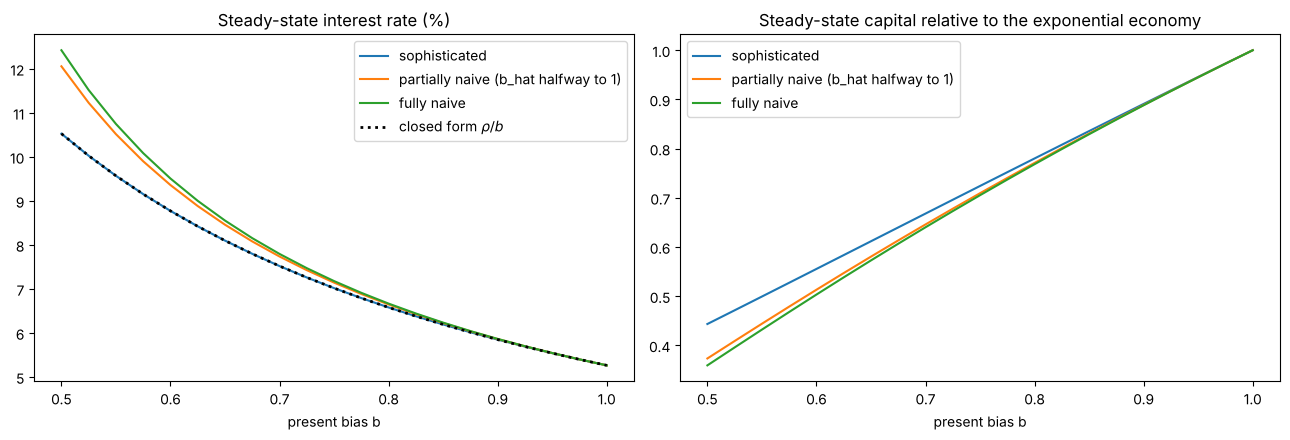

In [5]:
b_grid = np.linspace(0.5, 1.0, 21)
cases_b = {'sophisticated': lambda b: dict(beta_pb=b, beta_pb_hat=b),
           'partially naive (b_hat halfway to 1)': lambda b: dict(beta_pb=b, beta_pb_hat=b + 0.5 * (1 - b)),
           'fully naive': lambda b: dict(beta_pb=b, beta_pb_hat=1.0)}
k_exp = get_settings(beta_pb=1.0, beta_pb_hat=1.0).k_ss

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
for name, kw in cases_b.items():
    ss_b = [get_settings(**kw(b_)) for b_ in b_grid]
    ax[0].plot(b_grid, [100 * (s_.R_ss - 1) for s_ in ss_b], label=name)
    ax[1].plot(b_grid, [s_.k_ss / k_exp for s_ in ss_b], label=name)
ax[0].plot(b_grid, 100 * (1 / 0.95 - 1) / b_grid, 'k:', lw=2, label=r'closed form $\rho / b$')
ax[0].set(title='Steady-state interest rate (%)', xlabel='present bias b')
ax[1].set(title='Steady-state capital relative to the exponential economy', xlabel='present bias b')
ax[0].legend()
ax[1].legend()
plt.tight_layout()
plt.show()

The steady-state interest rate rises steeply as $b$ falls: present bias of $b = 0.5$ doubles it, to about 10.5% for a sophisticated household and over 12% for a fully naive one. Capital falls correspondingly. The gap between naive and sophisticated households grows as present bias strengthens, because the more present-biased a household is, the more it matters whether it knows it.

### Pollak's equivalence

As a check on the theory, here are the steady-state interest rates for different curvatures $\gamma$. As $\gamma$ approaches one, the naive and sophisticated households converge. With $\gamma > 1$ naive households need a higher interest rate, with $\gamma < 1$ a lower one, as the income- and substitution-effect argument predicts. The sophisticated household's rate is $\rho/b$ in every case.

In [6]:
print(f'{"":10s}{"sophisticated":>15s}{"partially naive":>17s}{"fully naive":>13s}')
for g in (0.5, 0.9, 1.001, 1.5, 2.0, 4.0):
    rates = [100 * (get_settings(gamma=g, beta_pb=0.7, beta_pb_hat=bh).R_ss - 1) for bh in (0.7, 0.85, 1.0)]
    print(f'gamma={g:<5g}' + ''.join(f'{r_:{w}.3f}%' for r_, w in zip(rates, (14, 16, 12))))

            sophisticated  partially naive  fully naive
gamma=0.5           7.519%           7.157%       7.085%


gamma=0.9           7.519%           7.474%       7.464%
gamma=1.001         7.519%           7.519%       7.519%


gamma=1.5           7.519%           7.660%       7.697%
gamma=2             7.519%           7.736%       7.794%
gamma=4             7.519%           7.855%       7.951%


## The transition

### The equilibrium system

As in Lecture 1, we start the economy with capital below its steady state and solve for the whole path at once. The unknowns, in logs, are consumption $c_0, \ldots, c_T$ and capital $k_1, \ldots, k_{T+1}$: $2T + 2$ unknowns. The equations are:

| Block | Equation | Periods | Count |
|---|---|---|---|
| Resource constraint | $k_{t+1} = f(k_t) + (1-\delta) k_t - c_t$ | $0..T$ | $T+1$ |
| Consumption rule | $c_t = m_t W_t$ | $0..T$ | $T+1$ |

Given a guessed capital path, the **household block** computes everything the consumption rule needs, as a CGE model computes derived prices before evaluating its residuals:

1. prices $R_t$ and $w_t$ from the firm's conditions,
2. human wealth $H_t$ by backward recursion from its steady-state value,
3. the value coefficients $\varphi_t$ by backward recursion with the perceived MPCs $\hat m_t$,
4. the actual MPCs $m_t$, and total wealth $W_t = R_t k_t + H_t$.

**The terminal condition** differs from Lecture 1. There, $k_{T+1} = k_{ss}$ was imposed directly. Here the household believes that prices will be at their steady-state values after $T$, so $\varphi_{T+1} = \varphi_{ss}$ and $H_{T+1} = w_{ss} R_{ss}/(R_{ss} - 1)$, the value of a perpetual wage. The consumption rule then holds in every period up to $T$, and $k_{T+1}$ is free. If $T$ is long enough, the economy is at its steady state well before $T$.

### The code

In [7]:
def unpack(x, s):
    c = jnp.exp(x[:s.T + 1])
    k = jnp.concatenate([jnp.array([s.k0]), jnp.exp(x[s.T + 1:])])                          # k_0..k_{T+1}
    return c, k


def household_block(k, s):
    R = 1 + f_prime(k, s) - s.delta                                   # R_0..R_{T+1}
    w = f_prod(k, s) - k * f_prime(k, s)
    H_end = s.w_ss * s.R_ss / (s.R_ss - 1)
    _, H = jax.lax.scan(lambda Hn, wr: (wr[0] + Hn / wr[1],) * 2, H_end, (w[:-1], R[1:]), reverse=True)

    def step(phi_next, R_next):
        phi = phi_back(phi_next, R_next, s.beta, s.gamma, s.beta_pb_hat)
        return phi, (phi, phi_next)
    _, (phi, phi_next) = jax.lax.scan(step, s.phi_ss, R[1:], reverse=True)
    m = mpc(s.beta_pb, s.beta, s.gamma, phi_next, R[1:])               # actual MPC, t = 0..T
    m_hat = mpc(s.beta_pb_hat, s.beta, s.gamma, phi_next, R[1:])       # what the self believes it will do
    W = R[:-1] * k[:-1] + H
    return dict(R=R, w=w, H=H, W=W, phi=phi, phi_next=phi_next, m=m, m_hat=m_hat)


def transition_solve(x, s, solving=1):
    c, k = unpack(x, s)
    hh = household_block(k, s)
    resource = k[1:] - (f_prod(k[:-1], s) + (1 - s.delta) * k[:-1] - c)
    rule = jnp.log(c) - jnp.log(hh['m'] * hh['W'])
    errors = jnp.concatenate([resource, rule])
    if solving:
        return errors
    planned = hh['m_hat'][1:] * hh['W'][1:]                           # c_{t+1} as planned by self t
    econ = dict(hh, c=c, k=k, y=f_prod(k[:-1], s), planned_next=planned, overshoot=c[1:] / planned - 1,
                saving_rate=1 - c / f_prod(k[:-1], s), r=hh['R'] - 1)
    return errors, econ


def initial_guess(s):
    k = np.linspace(s.k0, s.k_ss, s.T + 2)[1:]
    return np.log(np.hstack((s.c_ss * np.ones(s.T + 1), k)))


def run_model(verbose=True, **kwargs):
    s = get_settings(**kwargs)
    f = lambda x: transition_solve(x, s, 1)
    x1 = newton(f, initial_guess(s), tol=1e-6, max_iter=500, adj=0.3)
    x = newton(f, x1, tol=1e-12, max_iter=100, adj=1)
    errors, econ = transition_solve(x, s, 0)
    econ = {key: np.asarray(v) for key, v in econ.items()}
    econ['max_error'] = float(jnp.max(jnp.abs(errors)))
    if verbose:
        print(f'beta_pb = {s.beta_pb}, beta_pb_hat = {s.beta_pb_hat}: R_ss - 1 = {100 * (s.R_ss - 1):.3f}%, '
              f'k_ss = {s.k_ss:.4f}, c_ss = {s.c_ss:.4f}; max |error| = {econ["max_error"]:.1e}')
    return s, econ


def euler_checks(s, e):
    # Two Euler equations the solution must satisfy (u' = c^-gamma):
    # partially naive:  u'(c_t) = beta_pb beta R_{t+1} u'(c_hat_{t+1}) [m_hat_{t+1} + (1 - m_hat_{t+1})/beta_pb_hat]
    # sophisticated (beta_pb_hat = beta_pb), Harris-Laibson generalised Euler:
    # u'(c_t) = beta R_{t+1} u'(c_{t+1}) [beta_pb m_{t+1} + 1 - m_{t+1}]
    up = lambda c: c ** (-s.gamma)
    c, R, m, mh = e['c'], e['R'], e['m'], e['m_hat']
    rhs = s.beta_pb * s.beta * R[1:-1] * up(e['planned_next']) * (mh[1:] + (1 - mh[1:]) / s.beta_pb_hat)
    out = {'naive Euler': np.max(np.abs(rhs / up(c[:-1]) - 1))}
    if s.beta_pb_hat == s.beta_pb:
        gee = s.beta * R[1:-1] * up(c[1:]) * (s.beta_pb * m[1:] + 1 - m[1:])
        out['generalised Euler'] = np.max(np.abs(gee / up(c[:-1]) - 1))
    return out

In [8]:
def plot(results, t_max=100):
    fig, ax = plt.subplots(2, 3, figsize=(16, 8))
    for label, (s, e) in results.items():
        line = ax[0, 0].plot(e['k'][:t_max], label=label)[0]
        ax[0, 0].axhline(s.k_ss, color=line.get_color(), ls=':', lw=0.8)
        ax[0, 1].plot(e['c'][:t_max])
        ax[0, 2].plot(100 * e['r'][:t_max])
        ax[1, 0].plot(e['m'][:t_max])
        ax[1, 1].plot(100 * e['saving_rate'][:t_max])
        ax[1, 2].plot(100 * e['overshoot'][:t_max])
    titles = ['Capital $k_t$ (dotted: own steady state)', 'Consumption $c_t$', 'Interest rate $r_t$ (%)',
              'Actual MPC out of total wealth $m_t$', 'Saving rate $1 - c/y$ (%)',
              "Consumption above what yesterday's self planned (%)"]
    for a_, t_ in zip(ax.flat, titles):
        a_.set_title(t_)
        a_.set_xlabel('t')
    ax[0, 0].legend()
    plt.tight_layout()
    plt.show()

### Results

We compare four households, all with $\beta = 0.95$ and $\gamma = 2$, starting from 30% of the exponential steady-state capital stock:

- an **exponential** household ($b = \hat b = 1$),
- a **sophisticated** present-biased household ($b = \hat b = 0.7$),
- a **partially naive** one ($b = 0.7$, $\hat b = 0.85$), and
- a **fully naive** one ($b = 0.7$, $\hat b = 1$).

In [9]:
b = 0.7
cases = {'exponential (b = 1)': dict(beta_pb=1.0, beta_pb_hat=1.0),
         f'sophisticated (b_hat = {b})': dict(beta_pb=b, beta_pb_hat=b),
         'partially naive (b_hat = 0.85)': dict(beta_pb=b, beta_pb_hat=0.85),
         'fully naive (b_hat = 1)': dict(beta_pb=b, beta_pb_hat=1.0)}
results = {label: run_model(**kw) for label, kw in cases.items()}

beta_pb = 1.0, beta_pb_hat = 1.0: R_ss - 1 = 5.263%, k_ss = 9.5758, c_ss = 1.9161; max |error| = 7.1e-15


beta_pb = 0.7, beta_pb_hat = 0.7: R_ss - 1 = 7.519%, k_ss = 6.3954, c_ss = 1.7168; max |error| = 4.4e-15


beta_pb = 0.7, beta_pb_hat = 0.85: R_ss - 1 = 7.736%, k_ss = 6.1839, c_ss = 1.7007; max |error| = 3.6e-15


beta_pb = 0.7, beta_pb_hat = 1.0: R_ss - 1 = 7.794%, k_ss = 6.1287, c_ss = 1.6964; max |error| = 2.7e-15


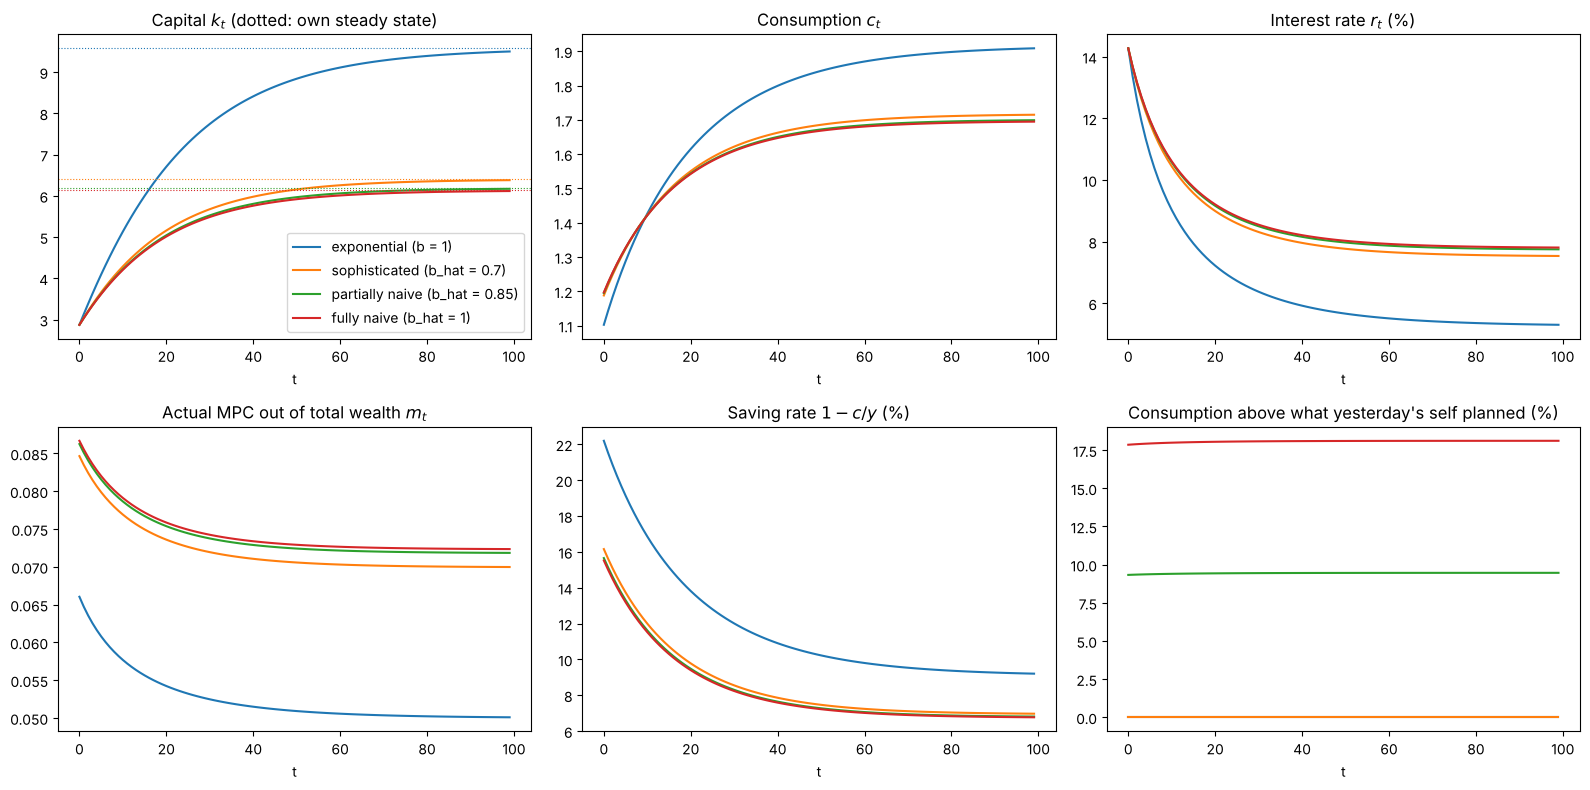

In [10]:
plot(results)

In [11]:
print(f'{"":32s}{"c_0":>7s}{"saving 0":>10s}{"m_0":>8s}{"m_hat_0":>9s}{"overshoot":>11s}{"k_50":>7s}{"k_ss":>7s}')
for label, (s_, e_) in results.items():
    print(f'{label:32s}{e_["c"][0]:7.3f}{100 * e_["saving_rate"][0]:9.1f}%{e_["m"][0]:8.4f}{e_["m_hat"][0]:9.4f}'
          f'{abs(100 * e_["overshoot"][0]):10.1f}%{e_["k"][50]:7.2f}{s_.k_ss:7.2f}')

                                    c_0  saving 0     m_0  m_hat_0  overshoot   k_50   k_ss
exponential (b = 1)               1.102     22.2%  0.0660   0.0660       0.0%   8.84   9.58
sophisticated (b_hat = 0.7)       1.188     16.2%  0.0846   0.0846       0.0%   6.15   6.40
partially naive (b_hat = 0.85)    1.195     15.7%  0.0862   0.0789       9.3%   5.97   6.18
fully naive (b_hat = 1)           1.197     15.5%  0.0867   0.0736      17.9%   5.92   6.13


**Present-biased households consume more and save less from the start.** With the same initial capital, they consume about 8% more at $t = 0$, and their saving rate is about 16% rather than 22%. Their marginal propensity to consume out of total wealth is about 0.085 rather than 0.066. Capital accumulates more slowly and converges to a steady state about a third lower. The interest rate stays higher throughout the transition, which partly offsets the present bias: the higher return makes saving more attractive.

**After an initial period, consumption is lower.** Because they invest less, present-biased economies have less capital, less output and eventually less consumption. Their consumption path crosses below the exponential economy's after about ten periods, and stays about 10% lower in the long run. Early consumption has been bought with permanently lower income.

**Naive households keep failing to follow their own plans.** The bottom-right panel compares each period's consumption with what the previous period's self planned for it.

- The **sophisticated** household's plans are always carried out.
- The **partially naive** household consumes about 9% more than planned, every period.
- The **fully naive** household consumes about 18% more than planned, every period.

The gap does not shrink. These households never learn: each self expects the next to be more patient, and each is disappointed. This is the pattern of procrastination that the evidence on gym memberships, retirement saving and commitment devices points to.

**Beliefs matter less than present bias itself.** All three present-biased economies look similar in aggregate. Naivete raises consumption a little and lowers capital a little, as the steady-state analysis predicted for $\gamma > 1$, but the main effect comes from $b$. What beliefs change most is the gap between plans and actions, which matters for welfare and for whether households would choose commitment devices.

### Checking the Euler equations

The solution was computed from the closed-form consumption rule. As an independent check, it should satisfy the Euler equations derived above: the partially naive one for every household, and the generalised Euler equation for the exponential and sophisticated ones.

In [12]:
for label, (s_, e_) in results.items():
    checks = euler_checks(s_, e_)
    print(f'{label:32s}' + '   '.join(f'{k}: max error {v:.1e}' for k, v in checks.items()))

exponential (b = 1)             naive Euler: max error 2.0e-15   generalised Euler: max error 1.1e-15
sophisticated (b_hat = 0.7)     naive Euler: max error 1.8e-15   generalised Euler: max error 1.3e-15
partially naive (b_hat = 0.85)  naive Euler: max error 2.0e-15
fully naive (b_hat = 1)         naive Euler: max error 1.9e-15


Both Euler equations hold to machine precision along the whole path.

## Welfare and policy

### Whose preferences count?

With exponential discounting, the competitive equilibrium is efficient: it solves the planning problem of Lecture 1. With present bias, it is not obvious what "efficient" means, because the household's selves disagree. Each self at date $t$ would like **future** selves to save more than they will, and would happily commit them to do so. But no self wants to save more **itself**.

A common approach is to evaluate welfare using the **long-run** preferences, discounting exponentially at $\beta$. These are the preferences every self holds about every period except its own (O'Donoghue and Rabin, 1999). By that criterion, present-biased households consume too much early on and accumulate too little capital. The exponential economy's path is what they would choose if they could commit.

### Commitment

That makes **commitment devices** valuable. A present-biased household would like a way to stop its future selves from undoing its plans. In the context of this lecture, forced saving, such as compulsory superannuation, or **illiquid** assets that are costly to draw down, play that role. Laibson (1997) called such illiquid assets **golden eggs**: they let a sophisticated household lock in saving that its future selves cannot easily spend.

This connects with [Lecture 5](05_two_asset_hank.ipynb), where the illiquid fund was modelled with an adjustment cost. With present-biased households, the fund's illiquidity would be valuable in itself, not just a cost.

### General equilibrium

In general equilibrium, the effects of present bias are partly offset by prices. Lower saving means less capital, a higher marginal product of capital and a higher interest rate, which encourages saving. The steady-state formula $r_{ss} = \rho/b$ shows the full effect for a sophisticated household: the interest rate has to rise until the effective discount factor $\beta[1 - (1-b) m]$ times the return equals one.

A policy that raises saving, say a compulsory saving rule, would raise capital, raise wages and lower the interest rate. Its welfare effect would include these price changes as well as the direct effect on each household's saving.

### Extensions

- **Commitment policy.** Add a forced saving rate or a saving subsidy, and find the one that restores the exponential path.
- **Heterogeneity.** Combine present bias with the incomplete markets of Lecture 5. With borrowing limits, naive present-biased households can end up permanently near the constraint, with high MPCs. Laibson, Maxted and Moll's work on present bias in HANK-style models suggests this can substantially change how monetary and fiscal policy work.
- **Welfare comparisons.** Compute each household's long-run welfare along each path, to quantify the cost of present bias and naivete.

## References

- Ashraf, N., Karlan, D. and Yin, W. (2006). Tying Odysseus to the mast: evidence from a commitment savings product in the Philippines. *Quarterly Journal of Economics*, 121(2), 635–672.
- DellaVigna, S. (2009). Psychology and economics: evidence from the field. *Journal of Economic Literature*, 47(2), 315–372.
- DellaVigna, S. and Linos, E. (2022). RCTs to scale: comprehensive evidence from two nudge units. *Econometrica*, 90(1), 81–116.
- DellaVigna, S. and Malmendier, U. (2006). Paying not to go to the gym. *American Economic Review*, 96(3), 694–719.
- Gabaix, X. (2020). A behavioral New Keynesian model. *American Economic Review*, 110(8), 2271–2327.
- Harris, C. and Laibson, D. (2001). Dynamic choices of hyperbolic consumers. *Econometrica*, 69(4), 935–957.
- Kahneman, D. and Tversky, A. (1979). Prospect theory: an analysis of decision under risk. *Econometrica*, 47(2), 263–291.
- Laibson, D. (1997). Golden eggs and hyperbolic discounting. *Quarterly Journal of Economics*, 112(2), 443–477.
- Loewenstein, G. and Prelec, D. (1992). Anomalies in intertemporal choice: evidence and an interpretation. *Quarterly Journal of Economics*, 107(2), 573–597.
- Madrian, B. C. and Shea, D. F. (2001). The power of suggestion: inertia in 401(k) participation and savings behavior. *Quarterly Journal of Economics*, 116(4), 1149–1187.
- O'Donoghue, T. and Rabin, M. (1999). Doing it now or later. *American Economic Review*, 89(1), 103–124.
- O'Donoghue, T. and Rabin, M. (2001). Choice and procrastination. *Quarterly Journal of Economics*, 116(1), 121–160.
- Phelps, E. S. and Pollak, R. A. (1968). On second-best national saving and game-equilibrium growth. *Review of Economic Studies*, 35(2), 185–199.
- Pollak, R. A. (1968). Consistent planning. *Review of Economic Studies*, 35(2), 201–208.
- Simon, H. A. (1955). A behavioral model of rational choice. *Quarterly Journal of Economics*, 69(1), 99–118.
- Strotz, R. H. (1956). Myopia and inconsistency in dynamic utility maximization. *Review of Economic Studies*, 23(3), 165–180.
- Thaler, R. H. (1981). Some empirical evidence on dynamic inconsistency. *Economics Letters*, 8(3), 201–207.
- Thaler, R. H. and Benartzi, S. (2004). Save More Tomorrow: using behavioral economics to increase employee saving. *Journal of Political Economy*, 112(S1), S164–S187.
- Thaler, R. H. and Sunstein, C. R. (2008). *Nudge: Improving Decisions about Health, Wealth, and Happiness*. Yale University Press.